In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels
import statsmodels.api as sm
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

# 1. Understanding the dataset

In [15]:
import warnings
warnings.filterwarnings('ignore')

In [16]:
# import numpy and pandas

import numpy as np
import pandas as pd

In [25]:
# read the csv file

advertising = pd.read_csv('/Users/riteshpardeshi/Downloads/advertising.csv')
advertising.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [27]:
# what is the shape of this dataframe

advertising.shape

(200, 4)

In [29]:
# the summary of null values in my dataframe

advertising.isna().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

# when we encounter null values in a dataframe - what are the actions that I can take on my null values

a - we can drop the column itself (a) when column is not required (b) assume 50% of the values in that column are missing 
b- we can drop the associated rows
c- we can impute the missing value with the most likely value.

In [32]:
# what are the datatypes of the columns 
advertising.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [34]:
advertising.dtypes

TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object

In [36]:
# summary statistics of the dataframe

advertising.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


# 2. Visualise the dataset

In [39]:
# import the libraries
import matplotlib.pyplot as plt
import seaborn as sns

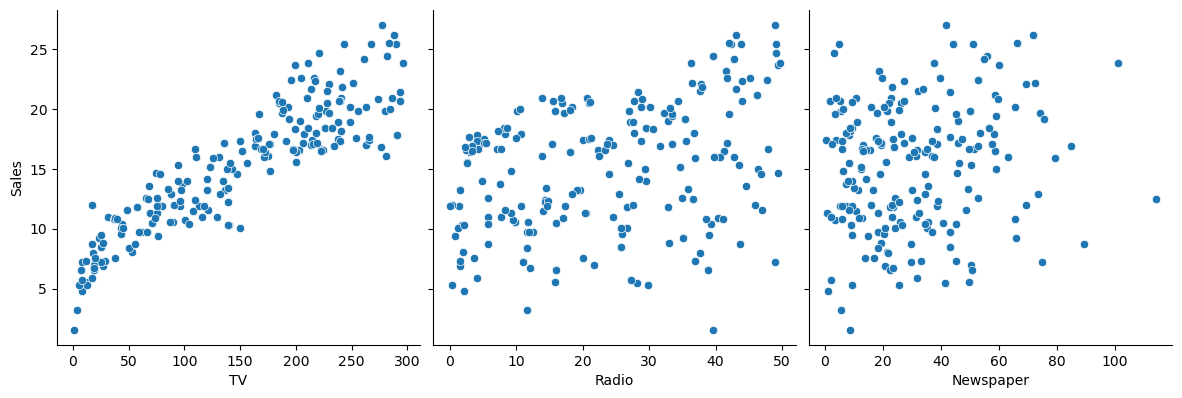

In [41]:
# draw a scatter plot of sales versus TV; sales versus Radio and sales versus newspaper

sns.pairplot(advertising, x_vars = ['TV','Radio','Newspaper'], y_vars = ['Sales'], size =4)

In [42]:
advertising.corr()

,TV,Radio,Newspaper,Sales
TV,1.000000,0.054809,0.056648,0.901208
Radio,0.054809,1.000000,0.354104,0.349631
Newspaper,0.056648,0.354104,1.000000,0.157960
Sales,0.901208,0.349631,0.157960,1.000000


<Axes: >

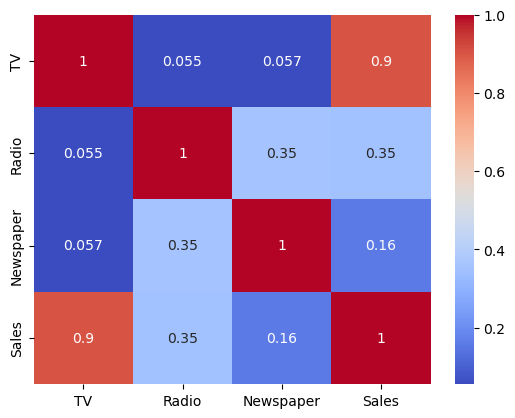

In [45]:
sns.heatmap(advertising.corr(),cmap ='coolwarm',annot =True)

# 3.building a simple linear regression model - sales as a function of TV

Y = mx + C

Sales = m * TV + C

- the model is going to give us the values of m and c



In [49]:
advertising.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [51]:
# defining the independent variable
X = advertising['TV']

In [53]:
# defining the dependent variable
y = advertising['Sales']

# This is a supervised ML model 
1. We do a train test split
2. we train on the training dataset
3. we apply on the test dataset

In [56]:
from sklearn.model_selection import train_test_split

In [58]:
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size = 0.7 , test_size = 0.3, random_state = 100)

# 4. Building the model using statsmodel

In [61]:
import statsmodels.api as sm

In [63]:
X_train_sm = sm.add_constant(X_train)

In [65]:
X_train_sm.head()

,const,TV
74,1.0,213.4
3,1.0,151.5
185,1.0,205.0
26,1.0,142.9
90,1.0,134.3


In [67]:
# fit the line of best fit using OLS - Residual sum of squares

lr = sm.OLS(y_train,X_train_sm).fit()

In [69]:
lr.params

const    6.948683
TV       0.054546
dtype: float64

In [71]:
lr.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Sales   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     611.2
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           1.52e-52
Time:                        19:49:37   Log-Likelihood:                -321.12
No. Observations:                 140   AIC:                             646.2
Df Residuals:                     138   BIC:                             652.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.9487      0.385     18.068      0.000       6.188       7.709
TV             0.0545      0.002     24.722      0.000       0.050       0.059
==============================================================================
Omnibus:                        0.027   Durbin-Watson:                   2.196
Prob(Omnibus):                  0.987   Jarque-Bera (JB):                0.150
Skew:                          -0.006   Prob(JB):                        0.928
Kurtosis:                       2.840   Cond. No.                         328.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

R-squared: how much of the variation in y does the model explain?
---------------------------------------------------------------------

Range: 0 to 1 (0% to 100%).

0 means the model explains nothing. It’s no better than predicting the average of y every time.
1 means it explains everything, and every point sits exactly on the line.
Your 0.816 means 81.6% of the ups and downs in Sales are accounted for by TV spend. The other 18.4% comes from things not in the model (radio, season, price, noise).

What counts as “good” depends on the field:

Field	Typical acceptable R²
Physics, engineering, controlled experiments	> 0.90
Business, marketing, sales	0.50 – 0.85
Economics, finance	0.30 – 0.70
Social sciences, psychology, human behaviour	0.10 – 0.40
Stock returns, very noisy systems	< 0.10 can still be useful

# Sales = 0.05 * TV + 6.94

- With every 1 unit increase in TV advertisements spend, the Sales will go up by 0.05 units
- If 0 value is invested in TV advertisement the sales will be 6.94 units

y_train_pred = lr.predict(X_train_sm)
y_train_pred

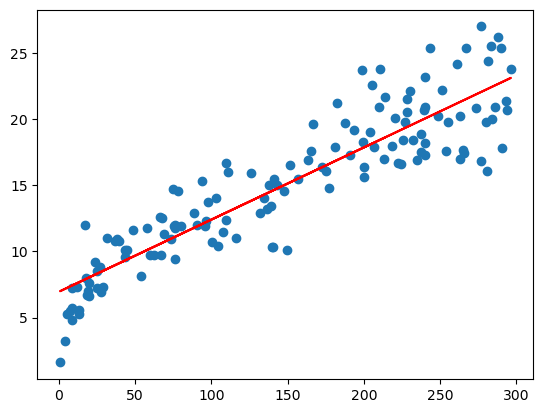

In [76]:
plt.scatter(X_train, y_train)
plt.plot(X_train, 6.948683 + 0.054546*X_train, 'r')

# 4. Residual Analysis

In [85]:
X_train.head()

74     213.4
3      151.5
185    205.0
26     142.9
90     134.3
Name: TV, dtype: float64

In [87]:
y_train_pred = 6.94 + 0.05 * X_train

In [89]:
y_train_pred.head()

74     17.610
3      14.515
185    17.190
26     14.085
90     13.655
Name: TV, dtype: float64

In [91]:
res = y_train - y_train_pred
res.head()

74    -0.610
3      1.985
185    5.410
26     0.915
90     0.345
dtype: float64

<Axes: ylabel='Density'>

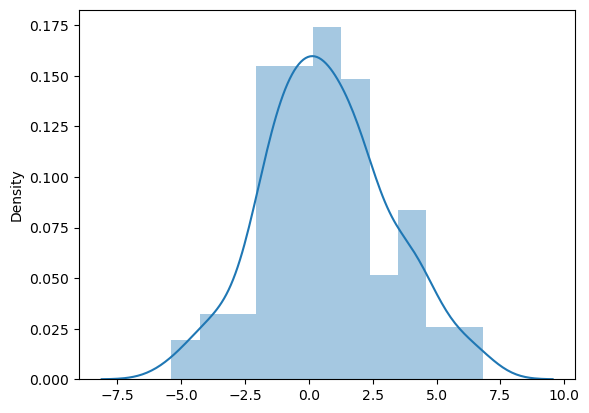

In [93]:
sns.distplot(res)

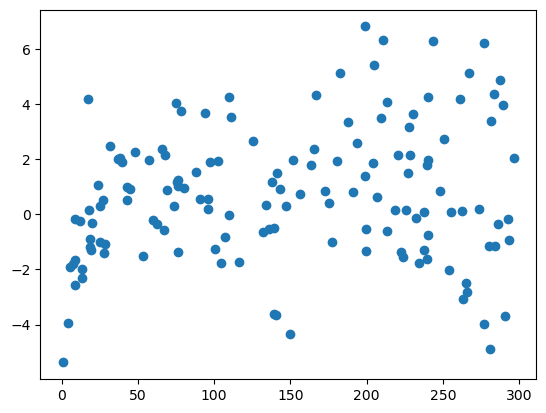

In [95]:
plt.scatter(X_train,res)

In [ ]:
# Apply the model to the test dataset

In [97]:
X_test_sm = sm.add_constant(X_test)

In [99]:
X_test_sm.head()

,const,TV
126,1.0,7.8
104,1.0,238.2
99,1.0,135.2
92,1.0,217.7
111,1.0,241.7


In [101]:
y_test_pred = lr.predict(X_test_sm)

In [103]:
y_test_pred.head()

126     7.374140
104    19.941482
99     14.323269
92     18.823294
111    20.132392
dtype: float64

In [105]:
# How well does the model fit on the test dataset (1st Metric - Rsquare)

In [107]:
rsquared = r2_score(y_true=y_test,y_pred=y_test_pred)

In [109]:
rsquared

0.7921031601245658

In [111]:
r_train_squared = r2_score(y_true=y_train,y_pred=y_train_pred)

In [113]:
r_train_squared

0.7953139385652735

In [115]:
# How well does the model fit on the test dataset (2nd Metric - RMSE)

In [143]:
mse_test = mean_squared_error(y_true=y_test,y_pred=y_test_pred)

In [145]:
mse_test

4.077556371826956

In [151]:
RMSE_test = np.sqrt(mse_test)
RMSE_test

2.019296008966233

In [139]:
mse_train = mean_squared_error(y_true=y_train,y_pred=y_train_pred)

In [141]:
mse_train

6.391929642857141

In [153]:
RMSE_train = np.sqrt(mse_train)
RMSE_train

2.528226580600944

In [159]:
# plotting the model on test dataset

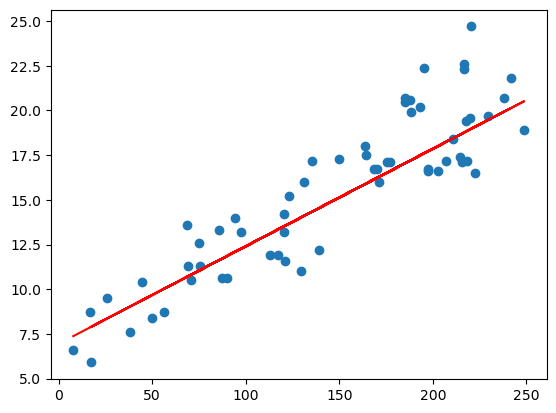

In [161]:
plt.scatter(X_test, y_test)
plt.plot(X_test, 6.948683 + 0.054546*X_test, 'r')